# 05_backtest：回測、成本、投組配置與覆蓋（驗證期）

設定與協定見 `setup.yaml`；程式在 `src/s05_backtest.py`。預設 `RUN = False` 只讀已存的結果。

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
R = ROOT / "results"
def show(name, n=60):
    p = R / f"{name}.csv"
    display(Markdown(f"**{name}**")); display(pd.read_csv(p, encoding="utf-8-sig").head(n)) if p.exists() else print("缺", name)
def fig(name, w=800):
    p = R / "figures" / name
    display(Image(filename=str(p), width=w)) if p.exists() else print("缺圖", name)

In [2]:
RUN = False
if RUN:
    from src import s05_backtest
    s05_backtest.main()

**05_val_main**

,策略,CAGR,vol,Sharpe,MDD,年換手(雙向),平均持有天數,下市出清
0,lgbm（淨）,0.190128,0.156863,1.188637,-0.350393,10.699461,53.490517,7.0
1,rule（淨）,0.038989,0.280407,0.277229,-0.638939,21.870195,22.657499,1.0
2,ridge（淨）,0.124597,0.120003,1.038886,-0.251962,5.852882,89.456012,11.0
3,ensemble（淨）,0.152027,0.124372,1.200607,-0.243275,11.658790,46.826021,7.0
4,lgbm（毛）,0.234676,0.156513,1.425904,-0.329290,10.992585,NaN,NaN
5,0050,0.152644,0.170023,0.920861,-0.339570,NaN,NaN,NaN
6,加權報酬指數,0.142953,0.154286,0.943659,-0.285525,NaN,NaN,NaN
7,可投資池等權,0.120405,0.188375,0.698669,-0.350012,NaN,NaN,NaN


**05_val_cost_sweep**

,成本倍數,每邊成本_bp,CAGR,vol,Sharpe,MDD
0,0.0,0.000,0.234676,0.156513,1.425904,-0.329290
1,0.5,19.625,0.212189,0.156578,1.307898,-0.339913
2,1.0,39.250,0.190128,0.156863,1.188637,-0.350393
3,2.0,78.500,0.147249,0.158061,0.948550,-0.370933
4,3.0,117.750,0.106069,0.160068,0.710200,-0.392148
5,4.0,157.000,0.065868,0.162961,0.473255,-0.415018


**05_val_breakeven**

,Unnamed: 0,值
0,毛年化,0.23467641061403155
1,0050 年化,0.15264363753737564
2,池等權年化,0.12040528473453582
3,年換手(雙向),10.992584966210215
4,假設每邊成本_bp,39.25
5,兩平成本_bp_對零,213.48610116309902
6,兩平成本_bp_對0050,74.6255528875274
7,兩平成本_bp_對池等權,103.95291574343105
8,成本區間（對 0050）,硬地板（< 2× 假設成本）
9,成本區間（對零）,安全（> 4×）


... (4 outputs left out)

**05_val_overlay**

,版本,CAGR,vol,Sharpe,MDD
0,無覆蓋,0.190128,0.156863,1.188637,-0.350393
1,波動目標,0.126661,0.103703,1.202287,-0.240762
2,停損階梯,0.147527,0.134868,1.088391,-0.322141


**05_val_realism**

,情境,CAGR,vol,Sharpe,MDD
0,基準（下市以最後價、漲跌停限制）,0.190128,0.156863,1.188637,-0.350393
1,下市折價 −50%,0.174057,0.158103,1.094528,-0.350393
2,不考慮漲跌停（樂觀）,0.189118,0.156906,1.182943,-0.350393


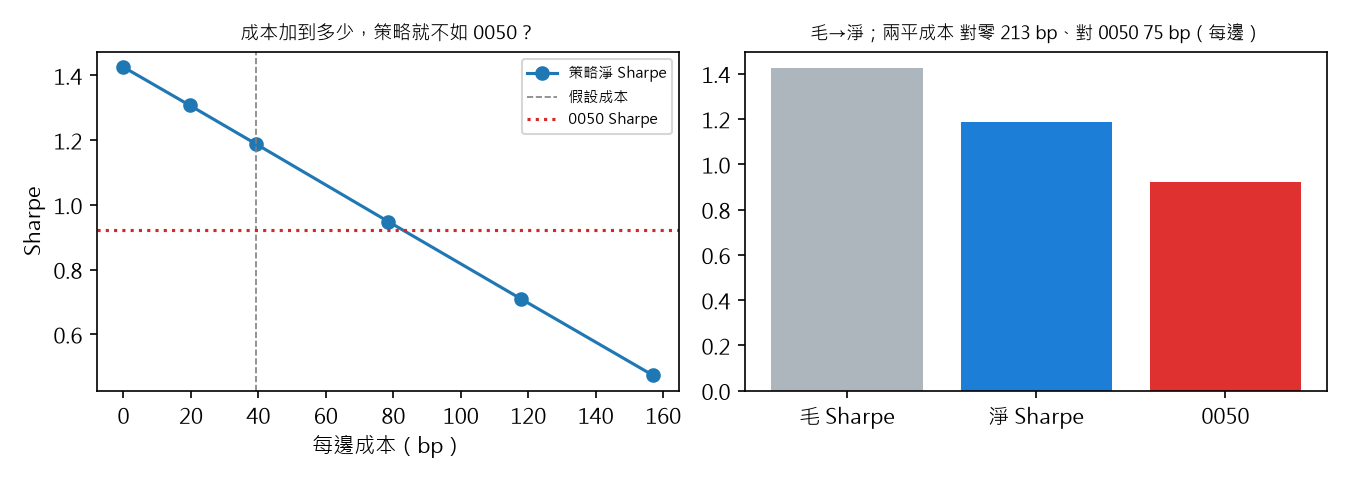

In [3]:
for t in ("main", "cost_sweep", "breakeven", "phases", "allocator", "overlay", "realism"): show(f"05_val_{t}")
fig("05_val_cost.png")